In [1]:
!pip install -q kagglehub

In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import classification_report
from sklearn.inspection import permutation_importance


sns.set_theme(style="whitegrid")

print("Bibliotecas importadas com sucesso!")


Bibliotecas importadas com sucesso!


In [3]:
import kagglehub


path = kagglehub.dataset_download(
    "atharvaingle/crop-recommendation-dataset"
)

print("Dataset baixado com sucesso!")
print(path)


Using Colab cache for faster access to the 'crop-recommendation-dataset' dataset.
Dataset baixado com sucesso!
/kaggle/input/crop-recommendation-dataset


In [4]:
import os

# Listar os arquivos baixados
for arquivo in os.listdir(path):
    print(arquivo)


Crop_recommendation.csv


In [5]:

# Carregar os dados
df = pd.read_csv(
    os.path.join(path, "Crop_recommendation.csv")
)

# Mostrar as primeiras linhas
df.head()


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


In [6]:

# Quantidade de linhas e colunas
print("Dimensões do dataset:", df.shape)

# Nomes das colunas
print("\nColunas:")
print(df.columns.tolist())

# Tipos de dados
print("\nInformações:")
df.info()


Dimensões do dataset: (2200, 8)

Colunas:
['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label']

Informações:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   object 
dtypes: float64(4), int64(3), object(1)
memory usage: 137.6+ KB


In [7]:

df.describe()


,N,P,K,temperature,humidity,ph,rainfall
count,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000
mean,50.551818,53.362727,48.149091,25.616244,71.481779,6.469480,103.463655
std,36.917334,32.985883,50.647931,5.063749,22.263812,0.773938,54.958389
min,0.000000,5.000000,5.000000,8.825675,14.258040,3.504752,20.211267
25%,21.000000,28.000000,20.000000,22.769375,60.261953,5.971693,64.551686
50%,37.000000,51.000000,32.000000,25.598693,80.473146,6.425045,94.867624
75%,84.250000,68.000000,49.000000,28.561654,89.948771,6.923643,124.267508
max,140.000000,145.000000,205.000000,43.675493,99.981876,9.935091,298.560117


In [8]:

# Verificar valores ausentes em cada coluna
df.isnull().sum()


,0
N,0
P,0
K,0
temperature,0
humidity,0
ph,0
rainfall,0
label,0


In [9]:

# Contar linhas duplicadas
print("Quantidade de duplicatas:", df.duplicated().sum())


Quantidade de duplicatas: 0


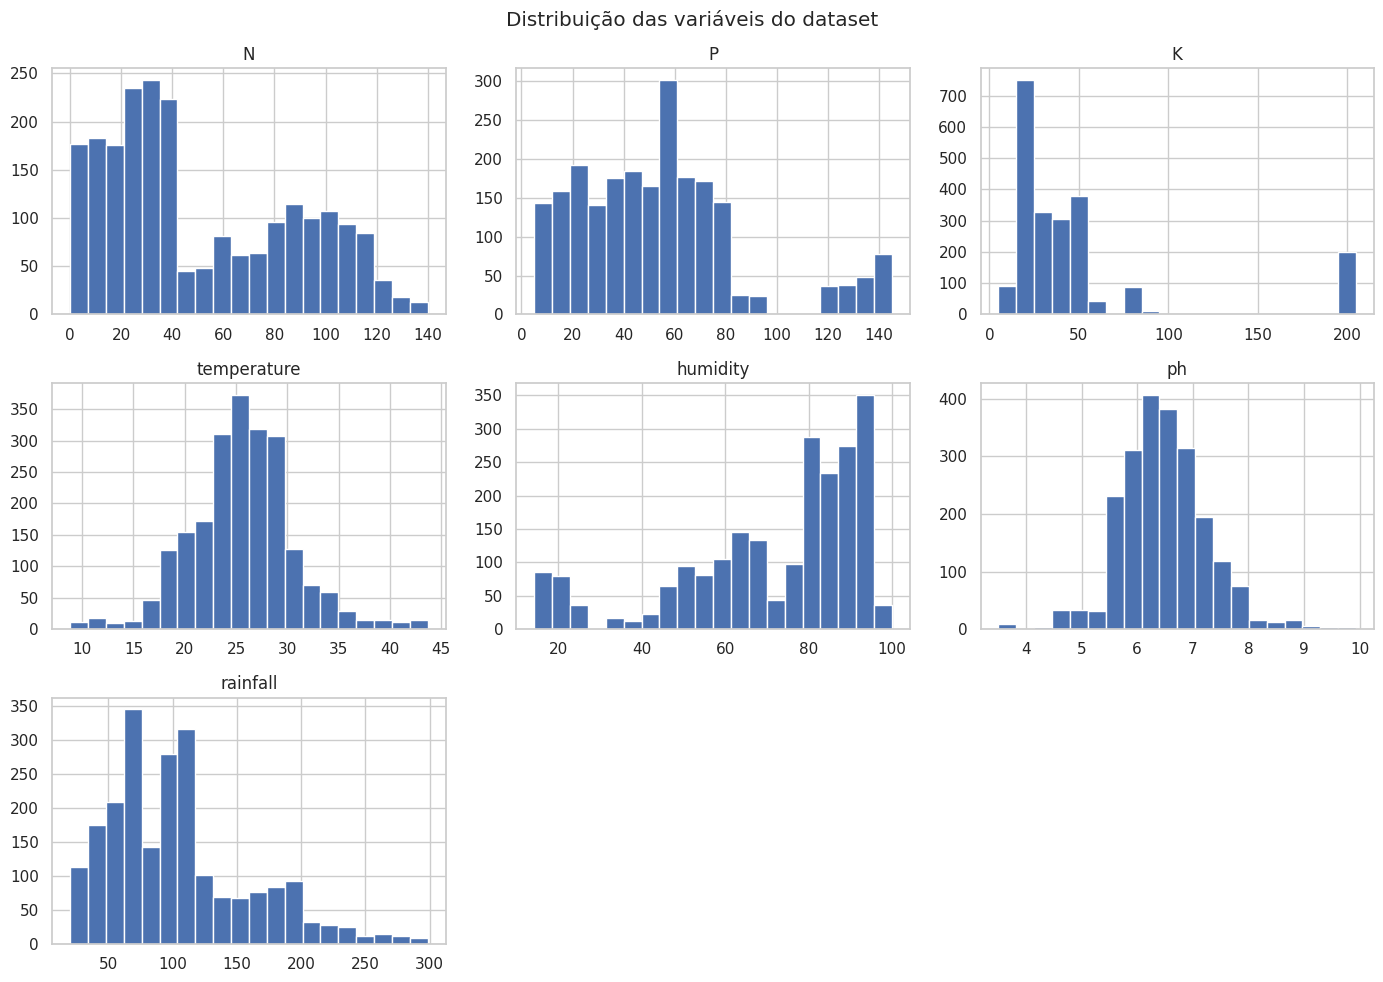

In [12]:

df.hist(figsize=(14, 10), bins=20)

plt.suptitle("Distribuição das variáveis do dataset")
plt.tight_layout()

plt.show()


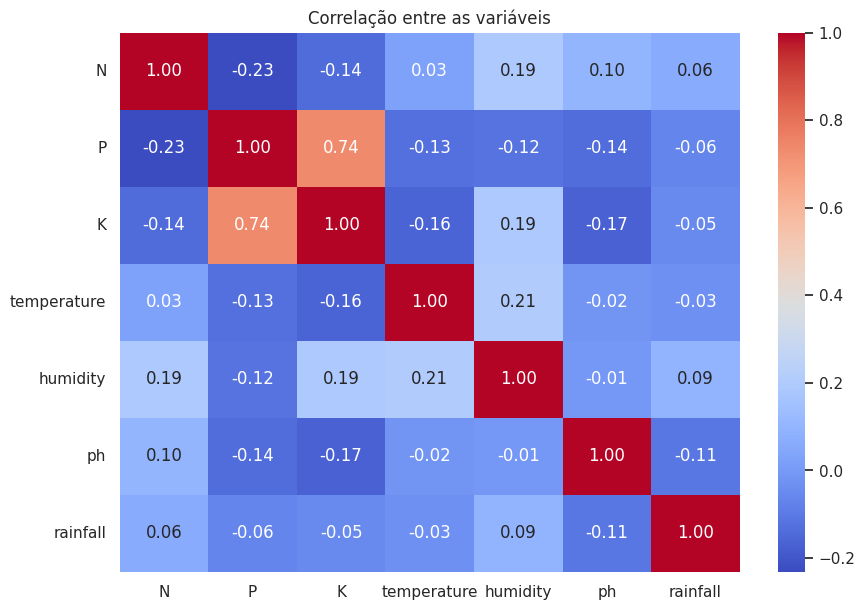

In [13]:
correlacao = df.drop(columns=["label"]).corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlacao,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlação entre as variáveis")
plt.show()


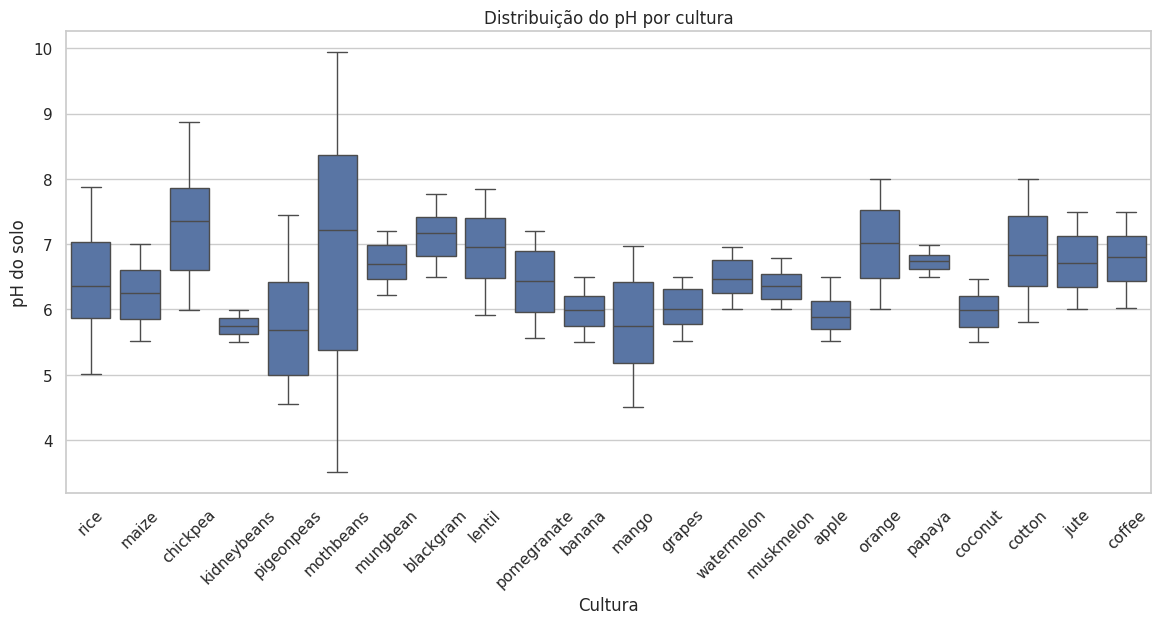

In [14]:

plt.figure(figsize=(14, 6))

sns.boxplot(
    data=df,
    x="label",
    y="ph"
)

plt.title("Distribuição do pH por cultura")
plt.xlabel("Cultura")
plt.ylabel("pH do solo")
plt.xticks(rotation=45)

plt.show()


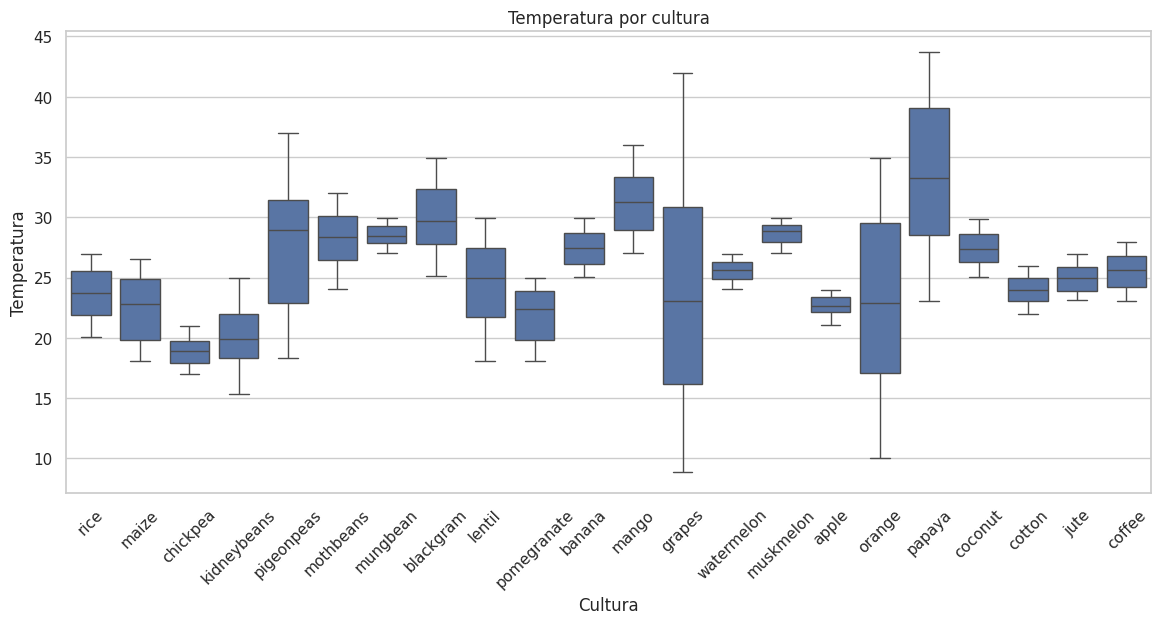

In [15]:

plt.figure(figsize=(14, 6))

sns.boxplot(
    data=df,
    x="label",
    y="temperature"
)

plt.title("Temperatura por cultura")
plt.xlabel("Cultura")
plt.ylabel("Temperatura")
plt.xticks(rotation=45)

plt.show()


In [16]:

X = df.drop(columns=["label"])

y = df["label"]

print("Formato de X:", X.shape)
print("Formato de y:", y.shape)


Formato de X: (2200, 7)
Formato de y: (2200,)


In [17]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Dados de treinamento:", X_train.shape)
print("Dados de teste:", X_test.shape)


Dados de treinamento: (1760, 7)
Dados de teste: (440, 7)


In [18]:

# Pipeline da Decision Tree
pipeline_arvore = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("modelo", DecisionTreeClassifier(random_state=42))
])

# Pipeline da Random Forest
pipeline_floresta = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("modelo", RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])

print("Pipelines criados com sucesso!")


Pipelines criados com sucesso!


In [19]:

# Treinar Decision Tree
pipeline_arvore.fit(X_train, y_train)

# Treinar Random Forest
pipeline_floresta.fit(X_train, y_train)

print("Os dois modelos foram treinados!")


Os dois modelos foram treinados!


In [20]:
pred_arvore = pipeline_arvore.predict(X_test)
pred_floresta = pipeline_floresta.predict(X_test)

print("Previsões realizadas!")


Previsões realizadas!


In [21]:

resultados = pd.DataFrame({
    "Modelo": ["Decision Tree", "Random Forest"],
    "Acurácia": [
        accuracy_score(y_test, pred_arvore),
        accuracy_score(y_test, pred_floresta)
    ]
})

resultados = resultados.sort_values(
    by="Acurácia",
    ascending=False
)

resultados


,Modelo,Acurácia
1,Random Forest,0.995455
0,Decision Tree,0.979545


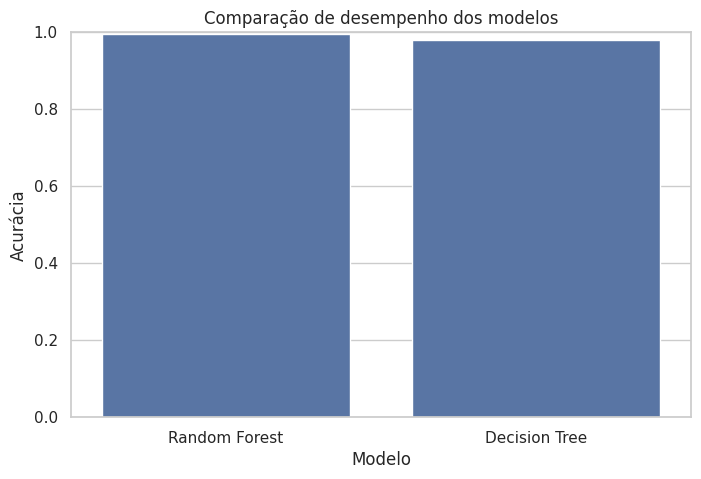

In [22]:

plt.figure(figsize=(8, 5))

sns.barplot(
    data=resultados,
    x="Modelo",
    y="Acurácia"
)

plt.title("Comparação de desempenho dos modelos")
plt.ylabel("Acurácia")
plt.ylim(0, 1)

plt.show()


In [23]:
print("RELATÓRIO — RANDOM FOREST")
print(classification_report(y_test, pred_floresta))


RELATÓRIO — RANDOM FOREST
              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      0.95      0.97        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
        jute       0.95      1.00      0.98        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       1.00      1.00      1.00        20
       maize       0.95      1.00      0.98        20
       mango       1.00      1.00      1.00        20
   mothbeans       1.00      1.00      1.00        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00      1.00      1.00        20
      orange       1.00      1.00      1.00        20
 

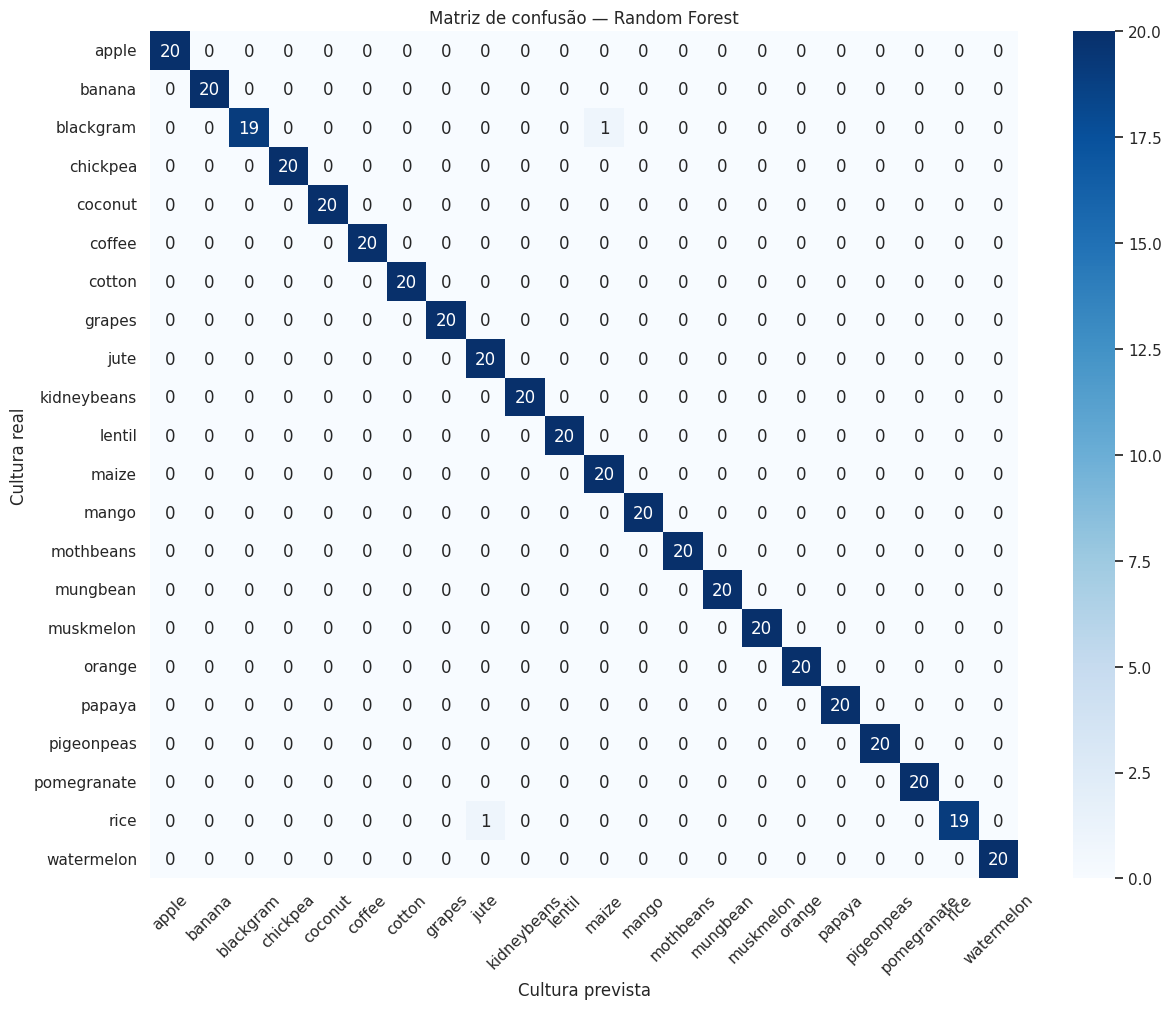

In [24]:
matriz = confusion_matrix(
    y_test,
    pred_floresta,
    labels=pipeline_floresta.classes_
)

plt.figure(figsize=(14, 11))

sns.heatmap(
    matriz,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=pipeline_floresta.classes_,
    yticklabels=pipeline_floresta.classes_
)

plt.title("Matriz de confusão — Random Forest")
plt.xlabel("Cultura prevista")
plt.ylabel("Cultura real")
plt.xticks(rotation=45)
plt.yticks(rotation=0)

plt.show()


In [25]:

importancia = permutation_importance(
    pipeline_floresta,
    X_test,
    y_test,
    n_repeats=20,
    random_state=42,
    scoring="accuracy"
)

importancias_df = pd.DataFrame({
    "Variavel": X_test.columns,
    "Importancia": importancia.importances_mean,
    "Desvio_Padrao": importancia.importances_std
})

importancias_df = importancias_df.sort_values(
    by="Importancia",
    ascending=False
)

importancias_df


,Variavel,Importancia,Desvio_Padrao
4,humidity,0.321023,0.018237
0,N,0.209659,0.016069
6,rainfall,0.196477,0.010501
2,K,0.136591,0.011829
1,P,0.107727,0.014788
5,ph,0.008523,0.004651
3,temperature,0.006705,0.003482


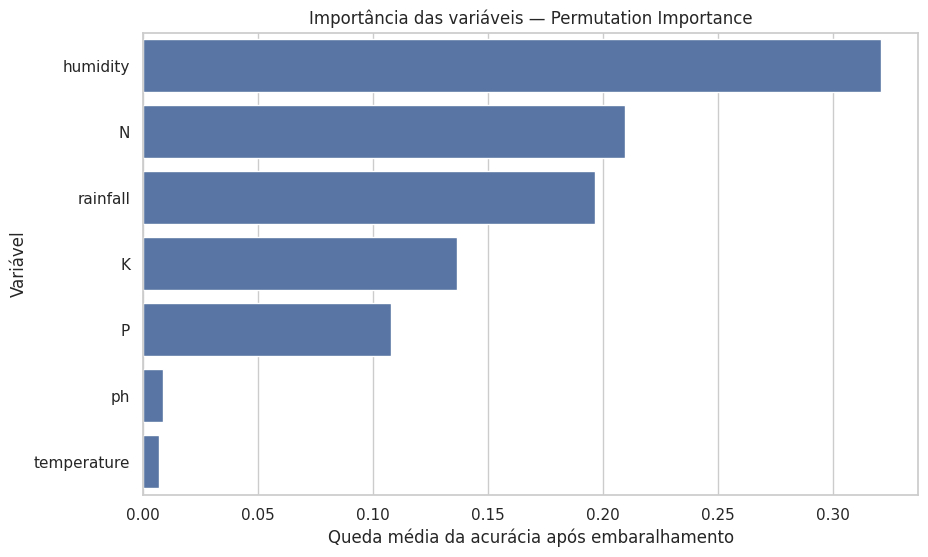

In [26]:

plt.figure(figsize=(10, 6))

sns.barplot(
    data=importancias_df,
    x="Importancia",
    y="Variavel"
)

plt.title("Importância das variáveis — Permutation Importance")
plt.xlabel("Queda média da acurácia após embaralhamento")
plt.ylabel("Variável")

plt.show()
